In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/elikplim/eergy-efficiency-dataset/ENB2012_data.csv


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import (
    StandardScaler,
    PolynomialFeatures,
    OneHotEncoder
)
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

In [3]:
df = pd.read_csv('/kaggle/input/datasets/elikplim/eergy-efficiency-dataset/ENB2012_data.csv')

df.head()

,X1,X2,X3,X4,X5,X6,X7,X8,Y1,Y2
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


In [4]:
X = df.drop(columns=['Y1', 'Y2'])
y = df['Y1']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (768, 8)
Target shape: (768,)


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (614, 8)
X_test: (154, 8)
y_train: (614,)
y_test: (154,)


In [6]:
categorical_features = ['X6', 'X8']

numerical_features = ['X1', 'X2', 'X3', 'X4', 'X5', 'X7']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)

Training shape: (614, 16)
Testing shape: (154, 16)


In [7]:
poly = PolynomialFeatures(degree=2, include_bias=False)

X_train_poly = poly.fit_transform(X_train_processed)
X_test_poly = poly.transform(X_test_processed)

print("Training shape:", X_train_poly.shape)
print("Testing shape:", X_test_poly.shape)

Training shape: (614, 152)
Testing shape: (154, 152)


In [8]:
#  Scaling the Target Variable (Heating Load)

# Create StandardScaler to normalize the target values
y_scaler = StandardScaler()

# Fit the scaler on training target data and transform it
y_train_scaled = y_scaler.fit_transform(
    y_train.to_numpy().reshape(-1, 1)
).ravel()

# Transform test target data using the same scaler
y_test_scaled = y_scaler.transform(
    y_test.to_numpy().reshape(-1, 1)
).ravel()

# Display the shapes of the scaled target data
print("y_train_scaled shape:", y_train_scaled.shape)
print("y_test_scaled shape:", y_test_scaled.shape)

y_train_scaled shape: (614,)
y_test_scaled shape: (154,)


In [9]:
# Step 8: Initialize SGD with Momentum

# Get the number of training samples and polynomial features
n_samples, n_features = X_train_poly.shape

# Initialize weights and bias with zeros
weights = np.zeros(n_features)
bias = 0.0

# Set hyperparameters
learning_rate = 0.001
epochs = 100
momentum = 0.9

# Initialize momentum velocities
velocity_w = np.zeros(n_features)
velocity_b = 0.0

# Store the training loss for each epoch
loss_history = []

In [10]:
# Check whether SGD initialization was completed
print("Initialization completed")
print("Number of features:", n_features)
print("Weights shape:", weights.shape)

Initialization completed
Number of features: 152
Weights shape: (152,)


In [11]:
# Step 9: Train SGD with Momentum

# Loop through the training epochs
for epoch in range(epochs):

    # Shuffle the training data at the beginning of each epoch
    indices = np.random.permutation(n_samples)
    X_shuffled = X_train_poly[indices]
    y_shuffled = y_train_scaled[indices]

    # Update weights using one sample at a time
    for i in range(n_samples):

        # Select one training sample
        x_i = X_shuffled[i]
        y_i = y_shuffled[i]

        # Calculate the prediction
        y_pred = np.dot(x_i, weights) + bias

        # Calculate the prediction error
        error = y_pred - y_i

        # Calculate gradients
        dw = 2 * error * x_i
        db = 2 * error

        # Update momentum velocities
        velocity_w = momentum * velocity_w + learning_rate * dw
        velocity_b = momentum * velocity_b + learning_rate * db

        # Update weights and bias
        weights -= velocity_w
        bias -= velocity_b

    # Calculate the loss after each epoch
    y_train_pred = np.dot(X_train_poly, weights) + bias
    loss = np.mean((y_train_pred - y_train_scaled) ** 2)
    loss_history.append(loss)

# Display the final training loss
print("Final Training Loss:", loss_history[-1])

Final Training Loss: 0.05400726266838007


In [12]:
# Step 10: Evaluate the SGD Model

# Make predictions on the test data
y_pred_scaled = np.dot(X_test_poly, weights) + bias

# Convert predictions back to the original scale
y_pred = y_scaler.inverse_transform(
    y_pred_scaled.reshape(-1, 1)
).ravel()

# Get the actual target values
y_test_original = y_test.to_numpy()

# Calculate evaluation metrics
mse = mean_squared_error(y_test_original, y_pred)
mae = mean_absolute_error(y_test_original, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_original, y_pred)

# Display the evaluation results
print("SGD Model Results:")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

SGD Model Results:
MAE: 2.0919806061728212
MSE: 6.906856053345321
RMSE: 2.6280898107456907
R2 Score: 0.9337354565911087


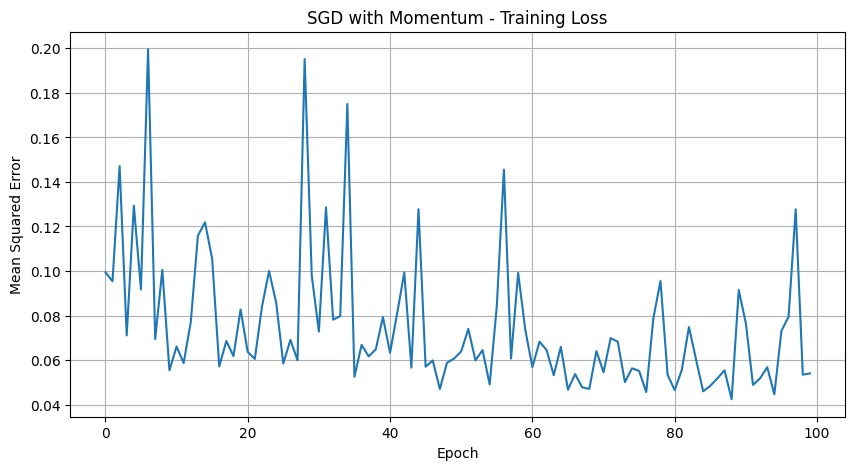

In [13]:
# Step 11: Plot the SGD Training Loss

# Create a figure for the loss curve
plt.figure(figsize=(10, 5))

# Plot the loss values across epochs
plt.plot(loss_history)

# Add chart title and axis labels
plt.title("SGD with Momentum - Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")

# Display the grid and plot
plt.grid(True)
plt.show()

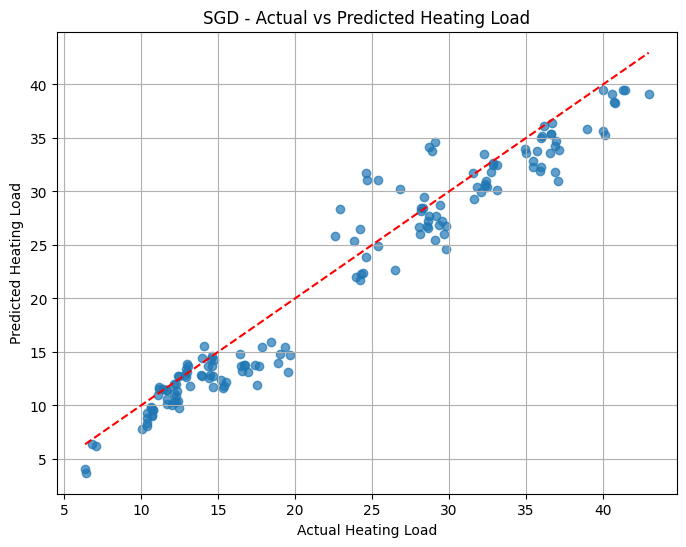

In [14]:
# Step 12: Plot Actual vs Predicted Values

# Create a figure for the comparison
plt.figure(figsize=(8, 6))

# Plot actual values against predicted values
plt.scatter(y_test_original, y_pred, alpha=0.7)

# Draw the ideal prediction line
plt.plot(
    [y_test_original.min(), y_test_original.max()],
    [y_test_original.min(), y_test_original.max()],
    'r--'
)

# Add chart title and axis labels
plt.title("SGD - Actual vs Predicted Heating Load")
plt.xlabel("Actual Heating Load")
plt.ylabel("Predicted Heating Load")

# Display the grid and plot
plt.grid(True)
plt.show()